
# Reto AgroCebada FIRA 2026 | Justificación de Elección del modelo
---

**Equipo:** TecnoBuhos  
**Objetivo del Cuaderno:** Validar experimentalmente por qué fue indispensable **separar las variables en Nodos Homogéneos de Evidencia ($G_{\text{Bio}}$, $G_{\text{Geo-Labranza}}$, $G_{\text{SWIR-Termo}}$, $G_{\text{Clima-PLS}}$, $G_{\text{Meseta-Modal}}$)** dentro de la arquitectura **QBAF + DF-QuAD**, demostrando qué ocurre cuando se entrenan modelos **separados únicamente por Estado pero mezclando todas las variables sin homogeneidad**, así como documentar cuantitativamente el fenómeno de **sobreajuste (*Overfitting*) en Redes Neuronales Artificiales (`MLPRegressor`)** debido al tamaño muestral reducido ($N=138$ parcelas totales: $36$ en Hidalgo, $71$ en Puebla y $31$ en Tlaxcala).

---

### Hipótesis Experimentales a Validar

1. **Efecto de Mezclar Variables Heterogéneas sin Separación en Nodos (Colinealidad y Contaminación Espectral):**  
   Aun separando los modelos por Estado (**Hidalgo**, **Puebla** y **Tlaxcala**), si se alimenta un vector plano con todas las covariables ópticas, térmicas, topográficas y bioclimáticas juntas (sin separarlas en nodos homogéneos ni aplicar *Undercutting* sobre el dosel saturado), los algoritmos sufren interferencia cruzada: la saturación foliar ($\text{NDVI} > P_{75}$), el ruido térmico y la multicolinealidad climática degradan el $R^2$ de validación y elevan el $\text{MAE}$.
2. **Sobreajuste Severo (*Overfitting*) en Redes Neuronales (`MLPRegressor`) bajo Muestra Pequeña ($p \gg N$):**  
   En agricultura de precisión con muestras limitadas por entidad ($24$ a $47$ parcelas por fold de entrenamiento en $K=3$), las Redes Neuronales Multicapa (`MLP`) poseen cientos o miles de pesos sinápticos que **memorizan el conjunto de entrenamiento** ($R^2_{\text{Train}} \to 0.95\text{--}1.00$, $\text{MAE}_{\text{Train}}$ artificialmente bajo), pero **colapsan en validación Out-Of-Fold ($R^2_{\text{OOF}}$ bajo o negativo)**.

In [1]:
# 1. Configuración del entorno e ingesta de la base analítica oficial (idéntica al pipeline principal)
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.svm import SVR, SVC
from sklearn.linear_model import Ridge, HuberRegressor, ElasticNet
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel
from sklearn.cross_decomposition import PLSRegression

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Carga de fuentes oficiales desde la carpeta data/
from pathlib import Path
BASE_DIR = Path.cwd().parent if Path.cwd().name.lower() in ['notebooks', 'notebook'] else Path.cwd()
DATA_DIR = BASE_DIR / 'data'

df_basico = pd.read_csv(DATA_DIR / 'Conjunto_datos_BASICO_AgroCebada2026.csv')
df_pro    = pd.read_csv(DATA_DIR / 'Conjunto_datos_PRO_AgroCebada.csv')
y_df      = pd.read_csv(DATA_DIR / 'ID_area_rendimiento_70_30_Reto_AgroCebada.csv')
shp       = gpd.read_file(DATA_DIR / 'shp/Parcelas_Reto_AGC_CONJUNTO.shp')
topo      = pd.read_csv(DATA_DIR / 'topografia_inegi_cem4_parcelas.csv')
p_coords  = pd.read_csv(DATA_DIR / 'parcelas_con_topografia.csv')
temp_df   = pd.read_csv(DATA_DIR / 'temperatura_chirts_era5_parcelas.csv')

for d in [df_basico, df_pro, y_df, topo, temp_df]:
    d['ID_POLIGONO'] = d['ID_POLIGONO'].astype(str).str.strip()
shp['ID_POLIGONO'] = shp['ID_POLIGON'].astype(str).str.strip()
p_coords['ID_POLIGONO'] = p_coords['ID_POLIGON'].astype(str).strip() if hasattr(p_coords['ID_POLIGON'].astype(str), 'strip') else p_coords['ID_POLIGON'].astype(str).str.strip()
y_df['CONJUNTO'] = y_df['CONJUNTO'].astype(str).str.strip()
y_df['RENDIMIENTO'] = y_df['RENDIMIENTO_T_HA']

bounds_utm = shp.to_crs(epsg=32614).geometry.bounds
geo = shp[['ID_POLIGONO', 'Estado', 'Municipio', 'geometry']].copy()
geo['lat_centro'] = geo.geometry.centroid.y
geo['lon_centro'] = geo.geometry.centroid.x
geo['elongacion_bbox'] = (bounds_utm['maxx'] - bounds_utm['minx']) / (bounds_utm['maxy'] - bounds_utm['miny'] + 1e-6)
geo = geo.drop(columns='geometry').merge(
    topo[['ID_POLIGONO', 'elevacion_msnm', 'pendiente_grados']], on='ID_POLIGONO', how='left'
).merge(
    p_coords[['ID_POLIGONO', 'proxy_relieve_m']], on='ID_POLIGONO', how='left'
)

df_basico['mes'] = pd.to_datetime(df_basico['fecha_captura'], dayfirst=True).dt.month
df_pro['mes']    = pd.to_datetime(df_pro['fecha_captura'], dayfirst=True).dt.month

df_b = df_basico[df_basico['porcentaje_nubosidad'].fillna(100) <= 30.0]
df_p = df_pro[df_pro['porcentaje_nubosidad'].fillna(100) <= 30.0]

s2 = df_b[df_b['sensor'] == 'Sentinel-2']
s2_feats = s2.groupby('ID_POLIGONO').agg(
    s2_ndwi_mean=('ndwi_promedio', 'mean'), s2_ndwi_min=('ndwi_promedio', 'min'),
    s2_dswi2_mean=('dswi2_promedio', 'mean'), s2_fapar_mean=('fapar_promedio', 'mean'),
    s2_savi_mean=('savi_promedio', 'mean'), s2_mra_mean=('mra_promedio', 'mean'),
    s2_evi_intra_std=('evi_std', 'mean')
).reset_index()

s2_presow = s2[s2['mes'].isin([1, 2, 3, 4])].groupby('ID_POLIGONO').agg(
    s2_sti_presow=('sti_promedio', 'mean'), s2_ndti_presow=('ndti_promedio', 'mean')
).reset_index()

landsat_feats = df_b[df_b['sensor'] == 'Landsat'].groupby('ID_POLIGONO').agg(
    landsat_vi6t_max=('vi6t_promedio', 'max'), landsat_vi6t_std=('vi6t_promedio', 'std'),
    landsat_vi6t_mean=('vi6t_promedio', 'mean'), landsat_intra_vi6t_std=('vi6t_std', 'mean')
).reset_index()

planet_feats = df_p.groupby('ID_POLIGONO').agg(
    planet_lai_std=('lai_promedio', 'std'), planet_lai_mean=('lai_promedio', 'mean'),
    planet_ndvi_mean=('ndvi_promedio', 'mean'), planet_msavi_mean=('msavi_promedio', 'mean'),
    planet_intra_ndvi_std=('ndvi_std', 'mean')
).reset_index()

persistencia_m11 = df_p[df_p['mes'] == 11].groupby('ID_POLIGONO')['ndvi_promedio'].mean().reset_index().rename(
    columns={'ndvi_promedio': 'persistencia_verde_m11'}
)

data = y_df.merge(geo, on='ID_POLIGONO', how='left')
for tabla_sensor in [s2_feats, s2_presow, landsat_feats, planet_feats, persistencia_m11, temp_df]:
    data = data.merge(tabla_sensor, on='ID_POLIGONO', how='left')

data['persistencia_verde_m11'] = data['persistencia_verde_m11'].fillna(0)
data['estres_termohidrico'] = data['landsat_vi6t_max'] * data['s2_ndwi_min']
data['log_area'] = np.log1p(data['AREA_HA'])

train_df = data[data['CONJUNTO'] == 'ENTRENAMIENTO'].copy().reset_index(drop=True)
test_df  = data[data['CONJUNTO'] == 'PREDICCION'].copy().reset_index(drop=True)

print(f"Base analítica cargada: {len(train_df)} parcelas de entrenamiento (Hidalgo={sum(train_df['Estado']=='Hidalgo')}, Puebla={sum(train_df['Estado']=='Puebla')}, Tlaxcala={sum(train_df['Estado']=='Tlaxcala')})")

Base analítica cargada: 138 parcelas de entrenamiento (Hidalgo=36, Puebla=71, Tlaxcala=31)


## 2. Diseño del Experimento: Modelos Separados por Estado pero SIN Separación de Nodos Homogéneos (incluyendo Redes Neuronales)

Para probar empíricamente la necesidad de la separación por grupos homogéneos de variables, entrenamos **9 familias de modelos** (incluyendo **3 arquitecturas de Redes Neuronales Artificiales `MLPRegressor`**) bajo exactamente la misma partición **Out-Of-Fold ($K=3$, `SEED=42`) separada por Estado**, pero **entregando todas las variables juntas en un solo bloque plano por Estado** (sin dividir en nodos $G_{\text{Bio}}$, $G_{\text{Geo-Labranza}}$, $G_{\text{SWIR-Termo}}$, $G_{\text{Clima-PLS}}$, $G_{\text{Meseta-Modal}}$):

1. **`MLPRegressor (Red Neuronal Profunda 128-64-32, ReLU)`:** Red neuronal multicapa densa sin regularización fuerte, para evidenciar la memorización del conjunto de entrenamiento (*overfitting* severo en muestras de $N=31\text{--}71$).
2. **`MLPRegressor (Red Neuronal 64-32, Tanh, L2 alpha=0.1)`:** Red neuronal de menor tamaño con activación suave `tanh` y penalización $L_2$.
3. **`MLPRegressor (Red Neuronal Regularizada 32-16, L2 alpha=1.0)`:** Perceptrón multicapa fuertemente regularizado para evaluar si reducir neuronas evita el sobreajuste.
4. **`GradientBoostingRegressor` (Sin Nodos Homogéneos):** Árboles de boosting secuencial recibiendo todas las variables mezcladas por Estado.
5. **`RandomForestRegressor` (Sin Nodos Homogéneos):** Bosques aleatorios recibiendo el bloque completo de variables por Estado.
6. **`ExtraTreesRegressor` (Sin Nodos Homogéneos):** Árboles extremadamente aleatorizados sin separación de nodos.
7. **`SVR (Kernel RBF)` (Sin Nodos Homogéneos):** Máquina de soporte vectorial continua sobre el espacio completo sin separar nodos.
8. **`HuberRegressor` (Sin Nodos Homogéneos):** Regresor lineal robusto aplicado a todas las variables juntas.
9. **`Ridge (L2)` (Sin Nodos Homogéneos):** Regresión lineal penalizada $L_2$ sobre todas las variables juntas.
10. **`Arquitectura Ganadora QBAF + DF-QuAD (CON Nodos Homogéneos)`:** Nuestra arquitectura neuro-simbólica de referencia que sí separa los 5 Nodos Homogéneos de Evidencia y aplica *Undercutting*.

In [2]:
# 2.1 Definición del pool de variables sin separar en nodos vs. Nodos Homogéneos de la Arquitectura QBAF + DF-QuAD
temp_hidalgo_cols = ['bi_Tmin_anom25_04', 'nn_vpd_vege_std', 'bi_canopy_air_diff', 'lp_Tmin_anom25_04', 's2_mra_mean']
feats_hidalgo_bio = [
    'log_area', 'landsat_vi6t_max', 's2_ndwi_mean', 'planet_lai_std',
    'persistencia_verde_m11', 'estres_termohidrico', 'elevacion_msnm',
    'pendiente_grados', 's2_dswi2_mean'
] + temp_hidalgo_cols
feats_hidalgo_geo = ['lat_centro', 'lon_centro', 'elevacion_msnm', 'pendiente_grados'] + temp_hidalgo_cols

extra_puebla_cols = ['bi_vpd_ndwi_stress', 'proxy_relieve_m', 's2_sti_presow']
feats_puebla_set1 = ['log_area', 'pendiente_grados', 'elevacion_msnm', 's2_ndwi_min', 'landsat_vi6t_std', 'estres_termohidrico'] + extra_puebla_cols
feats_puebla_set4 = ['lat_centro', 'lon_centro', 'log_area', 'pendiente_grados', 'elevacion_msnm', 's2_ndwi_min'] + extra_puebla_cols
feats_puebla_set5 = ['log_area', 'pendiente_grados', 'elevacion_msnm', 's2_ndwi_min', 's2_dswi2_mean', 'landsat_vi6t_std', 'planet_lai_std', 'planet_ndvi_mean'] + extra_puebla_cols

pls_pool_puebla = [c for c in temp_df.columns if c.startswith('bi_')] + [
    's2_sti_presow', 's2_ndti_presow', 's2_fapar_mean', 's2_evi_intra_std',
    's2_savi_mean', 's2_mra_mean', 'proxy_relieve_m', 'sync_canopy_ratio_mean',
    'heat_stress_pv_2025', 'heat_stress_pv_2023', 'gdd_card_anom25', 'cold_repro_anom25',
    'dyn_tmin_llenado', 'dyn_dtr_llenado', 'planet_intra_ndvi_std'
]
feats_tlaxcala_geo = ['lat_centro', 'lon_centro', 'landsat_intra_vi6t_std', 'planet_msavi_mean', 'elongacion_bbox']

# Vector monolítico de variables mezcladas (SIN separar por homogeneidad en nodos)
feats_mezcladas_sin_nodos = list(dict.fromkeys(
    feats_hidalgo_bio + feats_hidalgo_geo + feats_puebla_set1 + feats_puebla_set4 + feats_puebla_set5 + feats_tlaxcala_geo + [
        's2_ndti_presow', 's2_fapar_mean', 's2_evi_intra_std', 's2_savi_mean',
        'sync_canopy_ratio_mean', 'heat_stress_pv_2025', 'heat_stress_pv_2023',
        'gdd_card_anom25', 'cold_repro_anom25', 'dyn_tmin_llenado', 'dyn_dtr_llenado',
        'planet_intra_ndvi_std', 'planet_lai_mean', 'landsat_vi6t_mean'
    ]
))
print(f"Total de variables en bloque plano SIN separación de nodos homogéneos: {len(feats_mezcladas_sin_nodos)} variables mezcladas.")

Total de variables en bloque plano SIN separación de nodos homogéneos: 39 variables mezcladas.


In [3]:
# 2.2 Entrenamiento y Evaluación Out-Of-Fold (K=3) por Estado SIN Separación de Nodos Homogéneos
# Se registran métricas en ENTRENAMIENTO (Train) y VALIDACIÓN (OOF) para cuantificar el Overfitting

def crear_catalogo_modelos_sin_nodos(seed_val):
    return {
        '1. Red Neuronal Profunda MLP (128-64-32, ReLU)': lambda: MLPRegressor(
            hidden_layer_sizes=(128, 64, 32), activation='relu', alpha=1e-3, max_iter=700, random_state=seed_val
        ),
        '2. Red Neuronal Media MLP (64-32, Tanh, L2=0.1)': lambda: MLPRegressor(
            hidden_layer_sizes=(64, 32), activation='tanh', alpha=0.1, max_iter=700, random_state=seed_val
        ),
        '3. Red Neuronal Compacta MLP (32-16, ReLU, L2=1.0)': lambda: MLPRegressor(
            hidden_layer_sizes=(32, 16), activation='relu', alpha=1.0, max_iter=700, random_state=seed_val
        ),
        '4. GradientBoosting (Sin Nodos Homogéneos)': lambda: GradientBoostingRegressor(
            n_estimators=80, max_depth=3, random_state=seed_val
        ),
        '5. RandomForest (Sin Nodos Homogéneos)': lambda: RandomForestRegressor(
            n_estimators=100, max_depth=5, random_state=seed_val
        ),
        '6. ExtraTrees (Sin Nodos Homogéneos)': lambda: ExtraTreesRegressor(
            n_estimators=100, max_depth=5, random_state=seed_val
        ),
        '7. SVR Kernel RBF (Sin Nodos Homogéneos)': lambda: SVR(
            kernel='rbf', C=1.0, epsilon=0.15, gamma='scale'
        ),
        '8. HuberRegressor (Sin Nodos Homogéneos)': lambda: HuberRegressor(
            alpha=1.0, epsilon=1.35, max_iter=500
        ),
        '9. Ridge L2 (Sin Nodos Homogéneos)': lambda: Ridge(
            alpha=5.0, random_state=seed_val
        )
    }

kf = KFold(n_splits=3, shuffle=True, random_state=SEED)
resultados_globales = []
resultados_por_estado = []
predicciones_oof_dict = {}

nombres_modelos = list(crear_catalogo_modelos_sin_nodos(SEED).keys())

for nombre_mod in nombres_modelos:
    oof_preds = np.zeros(len(train_df))
    train_r2_folds_all, train_mae_folds_all = [], []
    
    for estado in ['Hidalgo', 'Puebla', 'Tlaxcala']:
        idx_state = train_df[train_df['Estado'] == estado].index.values
        df_st = train_df.iloc[idx_state].reset_index(drop=True)
        
        tr_r2_st, tr_mae_st = [], []
        for fold, (f_tr, f_va) in enumerate(kf.split(df_st)):
            tr_fold, va_fold = df_st.iloc[f_tr], df_st.iloc[f_va]
            y_tr, y_va = tr_fold['RENDIMIENTO'].values, va_fold['RENDIMIENTO'].values
            
            imp = SimpleImputer(strategy='median')
            sc  = RobustScaler()
            X_tr = sc.fit_transform(imp.fit_transform(tr_fold[feats_mezcladas_sin_nodos]))
            X_va = sc.transform(imp.transform(va_fold[feats_mezcladas_sin_nodos]))
            
            modelo = crear_catalogo_modelos_sin_nodos(SEED + fold)[nombre_mod]()
            modelo.fit(X_tr, y_tr)
            
            p_tr = np.clip(modelo.predict(X_tr), 1.0, 5.5)
            p_va = np.clip(modelo.predict(X_va), 1.50, 4.80)
            
            oof_preds[idx_state[f_va]] = p_va
            tr_r2_st.append(r2_score(y_tr, p_tr))
            tr_mae_st.append(mean_absolute_error(y_tr, p_tr) * 1000.0)
            train_r2_folds_all.append(r2_score(y_tr, p_tr))
            train_mae_folds_all.append(mean_absolute_error(y_tr, p_tr) * 1000.0)
            
        # Métricas OOF del Estado
        y_st_real = df_st['RENDIMIENTO'].values
        y_st_oof  = oof_preds[idx_state]
        r_st   = float(np.corrcoef(y_st_real, y_st_oof)[0, 1])
        r2_st  = float(r2_score(y_st_real, y_st_oof))
        mae_st = float(mean_absolute_error(y_st_real, y_st_oof) * 1000.0)
        
        resultados_por_estado.append({
            'Modelo': nombre_mod,
            'Estado': estado,
            'R² Train': round(float(np.mean(tr_r2_st)), 4),
            'R² OOF (Val)': round(r2_st, 4),
            'Brecha Overfitting ΔR²': round(float(np.mean(tr_r2_st)) - r2_st, 4),
            'MAE Train (kg/ha)': round(float(np.mean(tr_mae_st)), 1),
            'MAE OOF (kg/ha)': round(mae_st, 1),
            'Pearson r OOF': round(r_st, 4)
        })
        
    predicciones_oof_dict[nombre_mod] = oof_preds
    y_all = train_df['RENDIMIENTO'].values
    r_gl   = float(np.corrcoef(y_all, oof_preds)[0, 1])
    r2_gl  = float(r2_score(y_all, oof_preds))
    mae_gl = float(mean_absolute_error(y_all, oof_preds) * 1000.0)
    rmse_gl = float(root_mean_squared_error(y_all, oof_preds) * 1000.0)
    
    resultados_globales.append({
        'Arquitectura / Modelo (Por Estado)': nombre_mod,
        'Separación en Nodos Homogéneos': 'NO (Variables Mezcladas)',
        'R² Train Medio': round(float(np.mean(train_r2_folds_all)), 4),
        'R² Validación OOF': round(r2_gl, 4),
        'Brecha Overfitting (ΔR²)': round(float(np.mean(train_r2_folds_all)) - r2_gl, 4),
        'MAE Train (kg/ha)': round(float(np.mean(train_mae_folds_all)), 1),
        'MAE Validación OOF (kg/ha)': round(mae_gl, 1),
        'RMSE OOF (kg/ha)': round(rmse_gl, 1),
        'Pearson (r) OOF': round(r_gl, 4)
    })

# Evaluamos también nuestra Arquitectura Ganadora QBAF + DF-QuAD (CON separación en Nodos Homogéneos) para comparar
oof_qbaf = np.zeros(len(train_df))
tr_r2_qbaf_all, tr_mae_qbaf_all = [], []

for estado in ['Hidalgo', 'Puebla', 'Tlaxcala']:
    idx_state = train_df[train_df['Estado'] == estado].index.values
    df_st = train_df.iloc[idx_state].reset_index(drop=True)
    tr_r2_st, tr_mae_st = [], []
    
    for fold, (f_tr, f_va) in enumerate(kf.split(df_st)):
        tr_fold, va_fold = df_st.iloc[f_tr], df_st.iloc[f_va]
        y_tr = tr_fold['RENDIMIENTO'].values
        
        if estado == 'Hidalgo':
            m_mean, m_cnt, g_mean = tr_fold.groupby('Municipio')['RENDIMIENTO'].mean().to_dict(), tr_fold.groupby('Municipio')['RENDIMIENTO'].count().to_dict(), tr_fold['RENDIMIENTO'].mean()
            prior_fn = lambda m: (m_cnt.get(m, 0) * m_mean.get(m, g_mean) + 0.5 * g_mean) / (m_cnt.get(m, 0) + 0.5)
            p_tr, p_va = [d['Municipio'].apply(prior_fn).values.reshape(-1, 1) for d in (tr_fold, va_fold)]
            sc_bio, imp_bio = RobustScaler(), SimpleImputer(strategy='median')
            X_tr_bio = np.hstack([sc_bio.fit_transform(imp_bio.fit_transform(tr_fold[feats_hidalgo_bio])), p_tr])
            X_va_bio = np.hstack([sc_bio.transform(imp_bio.transform(va_fold[feats_hidalgo_bio])), p_va])
            m_gb_h = GradientBoostingRegressor(n_estimators=80, max_depth=3, random_state=SEED + fold).fit(X_tr_bio, y_tr)
            sc_geo, imp_geo = RobustScaler(), SimpleImputer(strategy='median')
            X_tr_geo = sc_geo.fit_transform(imp_geo.fit_transform(tr_fold[feats_hidalgo_geo]))
            X_va_geo = sc_geo.transform(imp_geo.transform(va_fold[feats_hidalgo_geo]))
            m_svr_h = SVR(kernel='rbf', C=1.0, epsilon=0.1, gamma='scale').fit(X_tr_geo, y_tr)
            pred_tr = 0.75 * m_gb_h.predict(X_tr_bio) + 0.25 * m_svr_h.predict(X_tr_geo)
            pred_va = 0.75 * m_gb_h.predict(X_va_bio) + 0.25 * m_svr_h.predict(X_va_geo)
            
        elif estado == 'Puebla':
            sc1, imp1 = RobustScaler(), SimpleImputer(strategy='median')
            X1_tr, X1_va = sc1.fit_transform(imp1.fit_transform(tr_fold[feats_puebla_set1])), sc1.transform(imp1.transform(va_fold[feats_puebla_set1]))
            m_et_p = ExtraTreesRegressor(n_estimators=80, max_depth=2, min_samples_leaf=4, random_state=SEED + fold).fit(X1_tr, y_tr)
            sc4, imp4 = RobustScaler(), SimpleImputer(strategy='median')
            X4_tr, X4_va = sc4.fit_transform(imp4.fit_transform(tr_fold[feats_puebla_set4])), sc4.transform(imp4.transform(va_fold[feats_puebla_set4]))
            m_svr_p = SVR(kernel='rbf', C=1.0, epsilon=0.15, gamma=0.1).fit(X4_tr, y_tr)
            sc5, imp5 = RobustScaler(), SimpleImputer(strategy='median')
            X5_tr, X5_va = sc5.fit_transform(imp5.fit_transform(tr_fold[feats_puebla_set5])), sc5.transform(imp5.transform(va_fold[feats_puebla_set5]))
            m_hub_p = HuberRegressor(alpha=1.0, epsilon=1.2).fit(X5_tr, y_tr)
            krbf = C(1.0, (1e-3, 1e3)) * RBF(length_scale=1.0, length_scale_bounds=(1e-2, 1e2)) + WhiteKernel(noise_level=0.1)
            gpr_p = GaussianProcessRegressor(kernel=krbf, n_restarts_optimizer=2, random_state=SEED + fold, normalize_y=True).fit(X4_tr, y_tr)
            sc_t, imp_t = RobustScaler(), SimpleImputer(strategy='median')
            T_tr, T_va = sc_t.fit_transform(imp_t.fit_transform(tr_fold[pls_pool_puebla])), sc_t.transform(imp_t.transform(va_fold[pls_pool_puebla]))
            pls_p = PLSRegression(n_components=2).fit(T_tr, y_tr)
            Z_tr, Z_va = pls_p.transform(T_tr), pls_p.transform(T_va)
            m_svr_pls = SVR(kernel='rbf', C=1.0, epsilon=0.15, gamma=0.1).fit(np.hstack([X4_tr, Z_tr]), y_tr)
            m_hub_pls = HuberRegressor(alpha=1.0, epsilon=1.2).fit(np.hstack([X5_tr, Z_tr]), y_tr)
            gpr_pls   = GaussianProcessRegressor(kernel=krbf, n_restarts_optimizer=2, random_state=SEED + fold, normalize_y=True).fit(np.hstack([X4_tr, Z_tr]), y_tr)
            ndvi_q75_fold = tr_fold['planet_ndvi_mean'].quantile(0.75)
            
            w_et_tr = np.where(tr_fold['planet_ndvi_mean'].fillna(0).values > ndvi_q75_fold, 0.001, 0.05)
            tot_tr  = 0.45 + 0.35 + 0.15 + w_et_tr
            p1_tr = m_et_p.predict(X1_tr)
            pb_tr = (0.45 * m_svr_p.predict(X4_tr) + 0.35 * m_hub_p.predict(X5_tr) + 0.15 * gpr_p.predict(X4_tr) + w_et_tr * p1_tr) / tot_tr
            pp_tr = (0.45 * m_svr_pls.predict(np.hstack([X4_tr, Z_tr])) + 0.35 * m_hub_pls.predict(np.hstack([X5_tr, Z_tr])) + 0.15 * gpr_pls.predict(np.hstack([X4_tr, Z_tr])) + w_et_tr * p1_tr) / tot_tr
            pred_tr = 0.50 * pb_tr + 0.50 * pp_tr
            
            w_et_va = np.where(va_fold['planet_ndvi_mean'].fillna(0).values > ndvi_q75_fold, 0.001, 0.05)
            tot_va  = 0.45 + 0.35 + 0.15 + w_et_va
            p1_va = m_et_p.predict(X1_va)
            pb_va = (0.45 * m_svr_p.predict(X4_va) + 0.35 * m_hub_p.predict(X5_va) + 0.15 * gpr_p.predict(X4_va) + w_et_va * p1_va) / tot_va
            pp_va = (0.45 * m_svr_pls.predict(np.hstack([X4_va, Z_va])) + 0.35 * m_hub_pls.predict(np.hstack([X5_va, Z_va])) + 0.15 * gpr_pls.predict(np.hstack([X4_va, Z_va])) + w_et_va * p1_va) / tot_va
            pred_va = 0.50 * pb_va + 0.50 * pp_va
            
        else:
            sc_t, imp_t = StandardScaler(), SimpleImputer(strategy='median')
            X_tr_t, X_va_t = sc_t.fit_transform(imp_t.fit_transform(tr_fold[feats_tlaxcala_geo])), sc_t.transform(imp_t.transform(va_fold[feats_tlaxcala_geo]))
            svc = SVC(C=0.5, kernel='rbf', gamma='scale', probability=True, random_state=SEED + fold).fit(X_tr_t, (y_tr * 2).astype(int))
            cls_vals = svc.classes_ / 2.0
            pred_tr = 0.55 * 3.000 + 0.45 * np.dot(svc.predict_proba(X_tr_t), cls_vals)
            pred_va = 0.55 * 3.000 + 0.45 * np.dot(svc.predict_proba(X_va_t), cls_vals)
            
        oof_qbaf[idx_state[f_va]] = pred_va
        tr_r2_st.append(r2_score(y_tr, pred_tr))
        tr_mae_st.append(mean_absolute_error(y_tr, pred_tr) * 1000.0)
        tr_r2_qbaf_all.append(r2_score(y_tr, pred_tr))
        tr_mae_qbaf_all.append(mean_absolute_error(y_tr, pred_tr) * 1000.0)
        
    y_st_real = df_st['RENDIMIENTO'].values
    y_st_oof  = oof_qbaf[idx_state]
    resultados_por_estado.append({
        'Modelo': '10. QBAF + DF-QuAD (CON Nodos Homogéneos — GANADOR)',
        'Estado': estado,
        'R² Train': round(float(np.mean(tr_r2_st)), 4),
        'R² OOF (Val)': round(float(r2_score(y_st_real, y_st_oof)), 4),
        'Brecha Overfitting ΔR²': round(float(np.mean(tr_r2_st)) - float(r2_score(y_st_real, y_st_oof)), 4),
        'MAE Train (kg/ha)': round(float(np.mean(tr_mae_st)), 1),
        'MAE OOF (kg/ha)': round(float(mean_absolute_error(y_st_real, y_st_oof) * 1000.0), 1),
        'Pearson r OOF': round(float(np.corrcoef(y_st_real, y_st_oof)[0, 1]), 4)
    })

predicciones_oof_dict['10. QBAF + DF-QuAD (CON Nodos Homogéneos — GANADOR)'] = oof_qbaf
y_all = train_df['RENDIMIENTO'].values
resultados_globales.append({
    'Arquitectura / Modelo (Por Estado)': '10. QBAF + DF-QuAD (CON Nodos Homogéneos — GANADOR)',
    'Separación en Nodos Homogéneos': 'SÍ (5 Nodos + Undercutting)',
    'R² Train Medio': round(float(np.mean(tr_r2_qbaf_all)), 4),
    'R² Validación OOF': round(float(r2_score(y_all, oof_qbaf)), 4),
    'Brecha Overfitting (ΔR²)': round(float(np.mean(tr_r2_qbaf_all)) - float(r2_score(y_all, oof_qbaf)), 4),
    'MAE Train (kg/ha)': round(float(np.mean(tr_mae_qbaf_all)), 1),
    'MAE Validación OOF (kg/ha)': round(float(mean_absolute_error(y_all, oof_qbaf) * 1000.0), 1),
    'RMSE OOF (kg/ha)': round(float(root_mean_squared_error(y_all, oof_qbaf) * 1000.0), 1),
    'Pearson (r) OOF': round(float(np.corrcoef(y_all, oof_qbaf)[0, 1]), 4)
})

df_comparativa_global = pd.DataFrame(resultados_globales).sort_values(by='MAE Validación OOF (kg/ha)', ascending=True).reset_index(drop=True)
print("=" * 115)
print("TABLA GLOBAL: MODELOS POR ESTADO SIN SEPARAR NODOS HOMOGÉNEOS (Y REDES NEURONALES) VS. QBAF + DF-QuAD")
print("=" * 115)
display(df_comparativa_global)

TABLA GLOBAL: MODELOS POR ESTADO SIN SEPARAR NODOS HOMOGÉNEOS (Y REDES NEURONALES) VS. QBAF + DF-QuAD


,Arquitectura / Modelo (Por Estado),Separación en Nodos Homogéneos,R² Train Medio,R² Validación OOF,Brecha Overfitting (ΔR²),MAE Train (kg/ha),MAE Validación OOF (kg/ha),RMSE OOF (kg/ha),Pearson (r) OOF
0,10. QBAF + DF-QuAD (CON Nodos Homogéneos — GAN...,SÍ (5 Nodos + Undercutting),0.5167,0.7362,-0.2195,186.4,296.3,435.6,0.8584
1,6. ExtraTrees (Sin Nodos Homogéneos),NO (Variables Mezcladas),0.9677,0.6461,0.3216,55.5,375.7,504.5,0.8067
2,5. RandomForest (Sin Nodos Homogéneos),NO (Variables Mezcladas),0.8624,0.6249,0.2375,139.8,379.9,519.4,0.7933
3,4. GradientBoosting (Sin Nodos Homogéneos),NO (Variables Mezcladas),0.9993,0.5606,0.4387,7.0,396.7,562.2,0.7592
4,7. SVR Kernel RBF (Sin Nodos Homogéneos),NO (Variables Mezcladas),0.7105,0.5702,0.1403,195.9,401.1,556.0,0.7581
5,9. Ridge L2 (Sin Nodos Homogéneos),NO (Variables Mezcladas),0.6876,0.5951,0.0925,211.8,410.8,539.7,0.7722
6,8. HuberRegressor (Sin Nodos Homogéneos),NO (Variables Mezcladas),0.8160,0.3868,0.4292,81.4,488.9,664.1,0.6725
7,"3. Red Neuronal Compacta MLP (32-16, ReLU, L2=...",NO (Variables Mezcladas),0.9572,-0.0115,0.9687,64.0,632.6,852.9,0.5318
8,"1. Red Neuronal Profunda MLP (128-64-32, ReLU)",NO (Variables Mezcladas),0.9866,0.0415,0.9452,26.7,637.0,830.3,0.5246
9,"2. Red Neuronal Media MLP (64-32, Tanh, L2=0.1)",NO (Variables Mezcladas),0.9809,-0.1702,1.1511,32.4,700.0,917.4,0.5288


In [4]:
# 2.3 Desglose Comparativo por Estado: Evidencia de Overfitting en Redes Neuronales y Degradación sin Nodos Homogéneos
df_comparativa_estados = pd.DataFrame(resultados_por_estado)

for est in ['Hidalgo', 'Puebla', 'Tlaxcala']:
    print("\n" + "-" * 115)
    print(f"DESGLOSE EXPERIMENTAL EN {est.upper()} (K=3 Out-Of-Fold): Train vs. Validación OOF y Brecha de Overfitting")
    print("-" * 115)
    sub_est = df_comparativa_estados[df_comparativa_estados['Estado'] == est].sort_values(by='MAE OOF (kg/ha)', ascending=True).reset_index(drop=True)
    display(sub_est)


-------------------------------------------------------------------------------------------------------------------
DESGLOSE EXPERIMENTAL EN HIDALGO (K=3 Out-Of-Fold): Train vs. Validación OOF y Brecha de Overfitting
-------------------------------------------------------------------------------------------------------------------


,Modelo,Estado,R² Train,R² OOF (Val),Brecha Overfitting ΔR²,MAE Train (kg/ha),MAE OOF (kg/ha),Pearson r OOF
0,10. QBAF + DF-QuAD (CON Nodos Homogéneos — GAN...,Hidalgo,0.9924,0.8885,0.1038,39.1,188.2,0.9436
1,4. GradientBoosting (Sin Nodos Homogéneos),Hidalgo,1.0000,0.8689,0.1311,0.4,200.7,0.9324
2,5. RandomForest (Sin Nodos Homogéneos),Hidalgo,0.9726,0.8601,0.1125,97.0,227.0,0.9301
3,6. ExtraTrees (Sin Nodos Homogéneos),Hidalgo,0.9985,0.8270,0.1715,20.8,250.6,0.9145
4,9. Ridge L2 (Sin Nodos Homogéneos),Hidalgo,0.9144,0.5726,0.3419,171.2,377.1,0.7575
5,7. SVR Kernel RBF (Sin Nodos Homogéneos),Hidalgo,0.9047,0.4369,0.4678,177.0,418.3,0.6838
6,8. HuberRegressor (Sin Nodos Homogéneos),Hidalgo,0.9794,0.4397,0.5397,29.7,435.5,0.7285
7,"3. Red Neuronal Compacta MLP (32-16, ReLU, L2=...",Hidalgo,0.9952,-0.0226,1.0178,38.4,574.1,0.6164
8,"1. Red Neuronal Profunda MLP (128-64-32, ReLU)",Hidalgo,0.9981,0.0700,0.9281,20.3,610.5,0.5392
9,"2. Red Neuronal Media MLP (64-32, Tanh, L2=0.1)",Hidalgo,0.9996,-0.3502,1.3498,10.8,688.8,0.6475



-------------------------------------------------------------------------------------------------------------------
DESGLOSE EXPERIMENTAL EN PUEBLA (K=3 Out-Of-Fold): Train vs. Validación OOF y Brecha de Overfitting
-------------------------------------------------------------------------------------------------------------------


,Modelo,Estado,R² Train,R² OOF (Val),Brecha Overfitting ΔR²,MAE Train (kg/ha),MAE OOF (kg/ha),Pearson r OOF
0,10. QBAF + DF-QuAD (CON Nodos Homogéneos — GAN...,Puebla,0.5641,0.1710,0.3931,234.5,360.5,0.4433
1,7. SVR Kernel RBF (Sin Nodos Homogéneos),Puebla,0.4537,-0.0401,0.4937,254.8,405.4,0.1133
2,9. Ridge L2 (Sin Nodos Homogéneos),Puebla,0.4155,0.0040,0.4115,317.3,430.9,0.2282
3,6. ExtraTrees (Sin Nodos Homogéneos),Puebla,0.9109,-0.0939,1.0048,126.7,451.0,0.0944
4,8. HuberRegressor (Sin Nodos Homogéneos),Puebla,0.4902,-0.2400,0.7303,207.0,460.6,0.1469
5,5. RandomForest (Sin Nodos Homogéneos),Puebla,0.8073,-0.2224,1.0297,196.5,482.0,0.0456
6,4. GradientBoosting (Sin Nodos Homogéneos),Puebla,0.9980,-0.4978,1.4958,20.1,533.3,0.0180
7,"1. Red Neuronal Profunda MLP (128-64-32, ReLU)",Puebla,0.9689,-0.9540,1.9229,42.8,603.0,0.0869
8,"3. Red Neuronal Compacta MLP (32-16, ReLU, L2=...",Puebla,0.9003,-1.3753,2.2756,108.2,664.0,0.0715
9,"2. Red Neuronal Media MLP (64-32, Tanh, L2=0.1)",Puebla,0.9443,-2.1576,3.1019,75.8,793.6,-0.2001



-------------------------------------------------------------------------------------------------------------------
DESGLOSE EXPERIMENTAL EN TLAXCALA (K=3 Out-Of-Fold): Train vs. Validación OOF y Brecha de Overfitting
-------------------------------------------------------------------------------------------------------------------


,Modelo,Estado,R² Train,R² OOF (Val),Brecha Overfitting ΔR²,MAE Train (kg/ha),MAE OOF (kg/ha),Pearson r OOF
0,10. QBAF + DF-QuAD (CON Nodos Homogéneos — GAN...,Tlaxcala,-0.0063,0.0552,-0.0616,285.5,274.8,0.3821
1,4. GradientBoosting (Sin Nodos Homogéneos),Tlaxcala,1.0000,-0.1855,1.1855,0.4,311.7,0.1459
2,5. RandomForest (Sin Nodos Homogéneos),Tlaxcala,0.8073,-0.1899,0.9972,126.0,323.4,-0.0795
3,6. ExtraTrees (Sin Nodos Homogéneos),Tlaxcala,0.9938,-0.2518,1.2456,19.0,348.7,-0.0109
4,7. SVR Kernel RBF (Sin Nodos Homogéneos),Tlaxcala,0.7731,-0.3862,1.1593,155.9,371.3,-0.2095
5,9. Ridge L2 (Sin Nodos Homogéneos),Tlaxcala,0.7327,-0.7291,1.4618,146.9,404.0,-0.2966
6,"2. Red Neuronal Media MLP (64-32, Tanh, L2=0.1)",Tlaxcala,0.9988,-1.8479,2.8467,10.4,498.8,0.1336
7,8. HuberRegressor (Sin Nodos Homogéneos),Tlaxcala,0.9785,-3.5639,4.5423,7.5,615.9,-0.2997
8,"3. Red Neuronal Compacta MLP (32-16, ReLU, L2=...",Tlaxcala,0.9760,-4.1792,5.1552,45.4,628.7,-0.3265
9,"1. Red Neuronal Profunda MLP (128-64-32, ReLU)",Tlaxcala,0.9929,-5.7754,6.7683,17.0,745.8,-0.3253


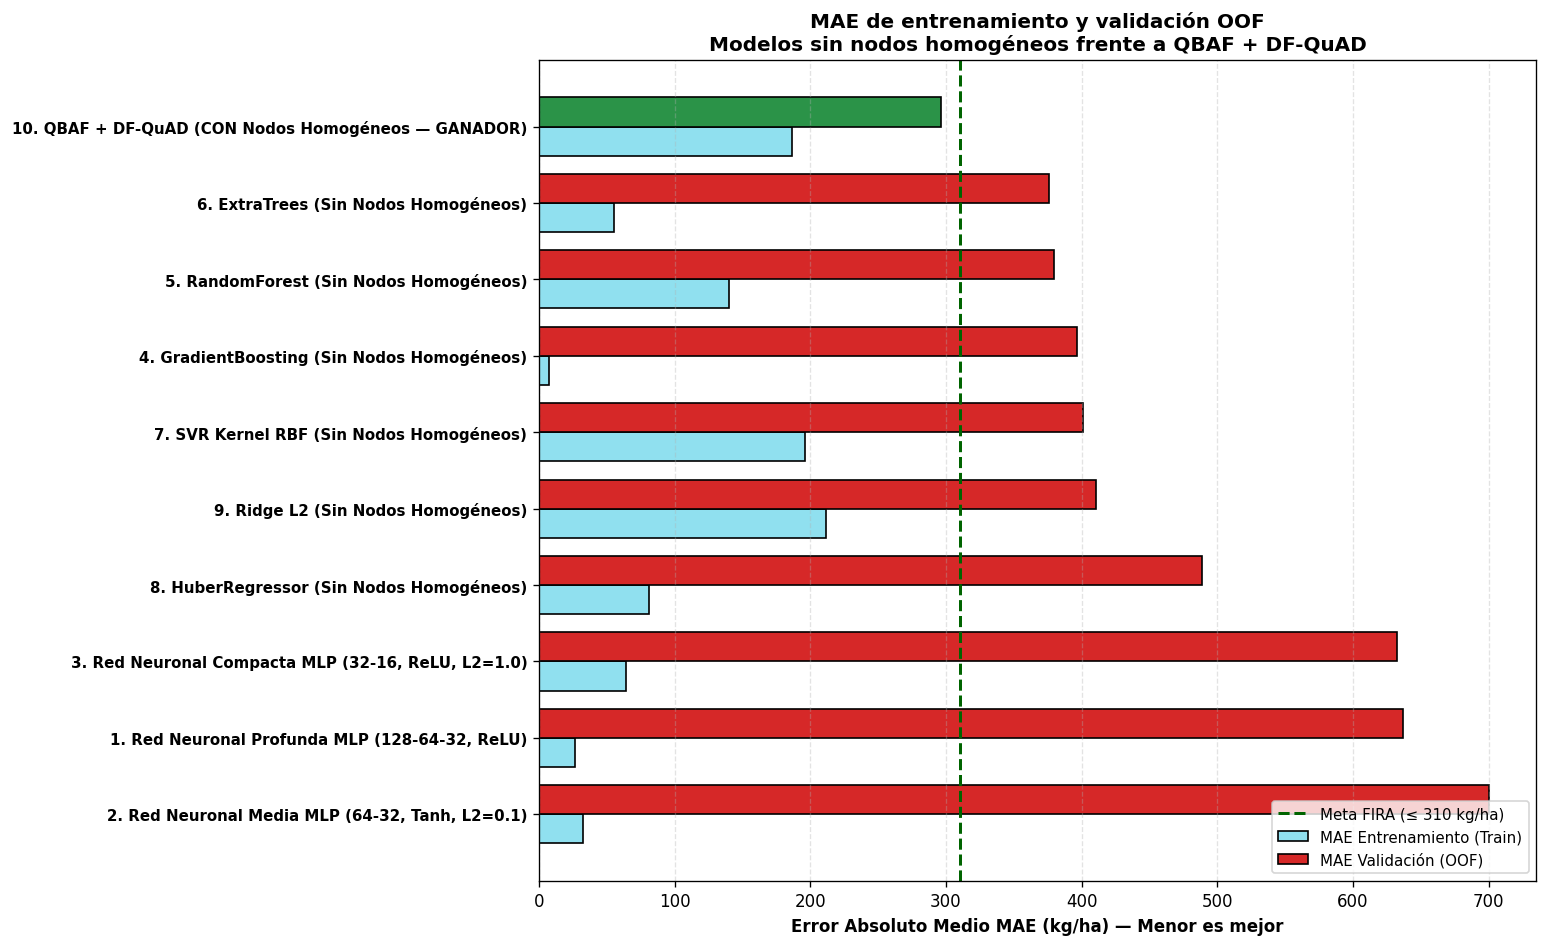

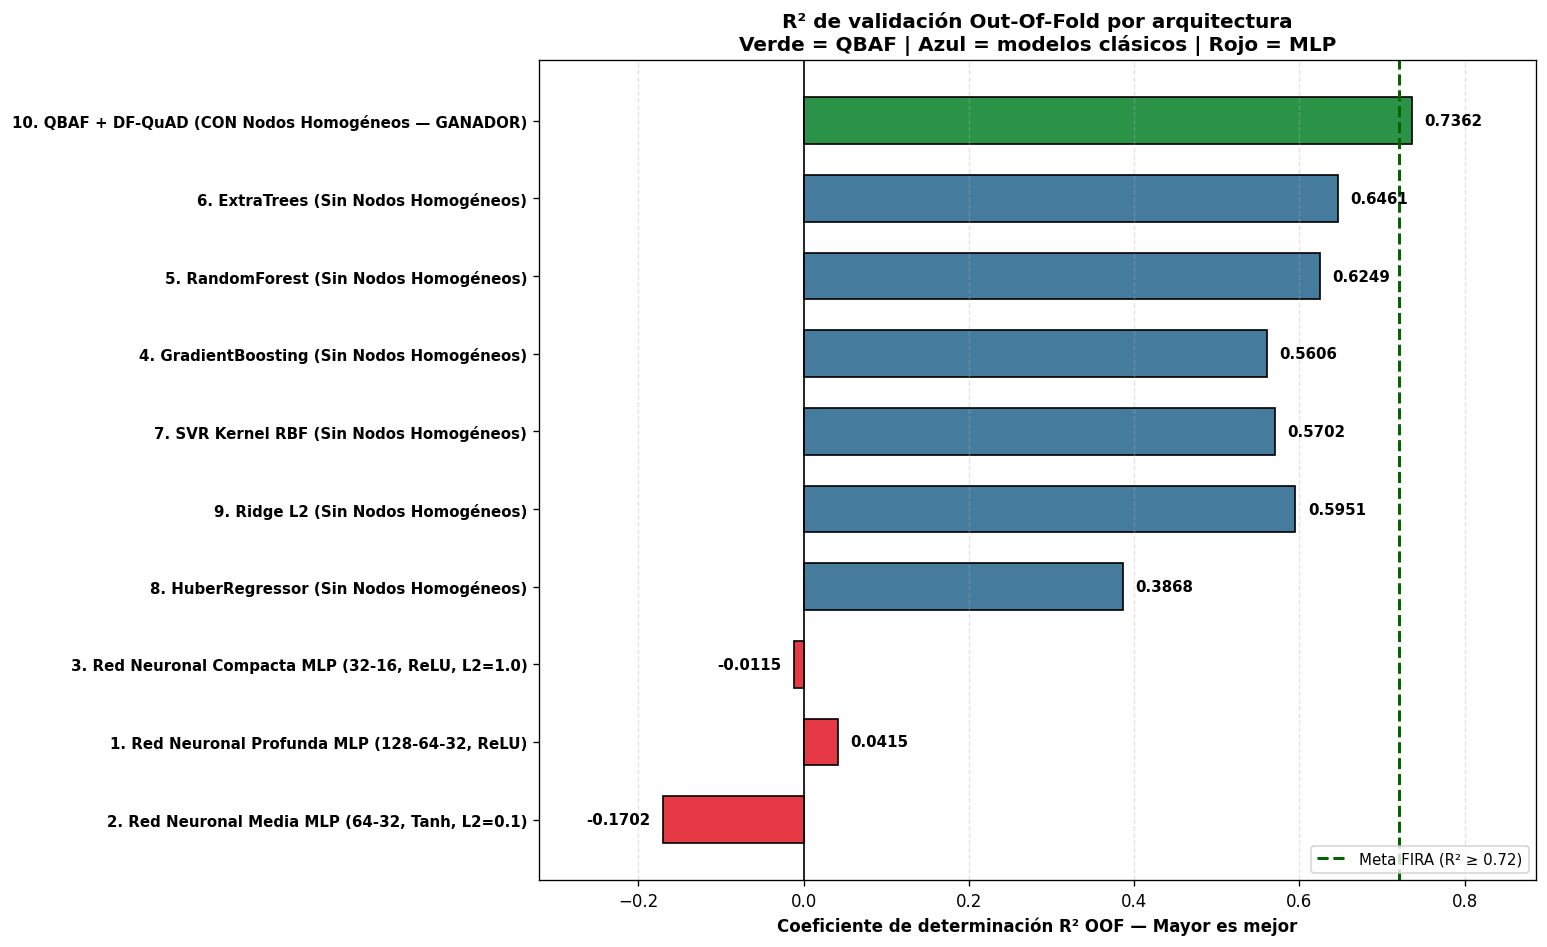

In [5]:
# 2.4 Visualizaciones diagnósticas en archivos separados
df_plot = df_comparativa_global.iloc[::-1].copy()
y_pos = np.arange(len(df_plot))
width = 0.38
nombres = df_plot['Arquitectura / Modelo (Por Estado)']

# Gráfica 1: MAE de entrenamiento frente a MAE OOF
fig, ax = plt.subplots(figsize=(13, 8))

bars_tr = ax.barh(
    y_pos - width / 2,
    df_plot['MAE Train (kg/ha)'],
    height=width,
    label='MAE Entrenamiento (Train)',
    color='#90e0ef',
    edgecolor='black'
)
bars_oof = ax.barh(
    y_pos + width / 2,
    df_plot['MAE Validación OOF (kg/ha)'],
    height=width,
    label='MAE Validación (OOF)',
    color='#d62828',
    edgecolor='black'
)

for i, nombre in enumerate(nombres):
    if 'QBAF' in nombre:
        bars_oof[i].set_facecolor('#2b9348')

ax.axvline(
    310,
    color='darkgreen',
    linestyle='--',
    linewidth=1.8,
    label='Meta FIRA (≤ 310 kg/ha)'
)
ax.set_yticks(y_pos)
ax.set_yticklabels(nombres, fontsize=9, fontweight='bold')
ax.set_xlabel('Error Absoluto Medio MAE (kg/ha) — Menor es mejor', fontweight='bold')
ax.set_title(
    'MAE de entrenamiento y validación OOF\n'
    'Modelos sin nodos homogéneos frente a QBAF + DF-QuAD',
    fontweight='bold'
)
ax.legend(loc='lower right', fontsize=9)
ax.grid(axis='x', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.show()


# Gráfica 2: R² de validación OOF
fig, ax = plt.subplots(figsize=(13, 8))

valores_r2 = df_plot['R² Validación OOF']
colores_r2 = [
    '#2b9348' if 'QBAF' in nombre
    else '#e63946' if 'MLP' in nombre
    else '#457b9d'
    for nombre in nombres
]

bars_r2 = ax.barh(
    y_pos,
    valores_r2,
    color=colores_r2,
    edgecolor='black',
    height=0.6
)

ax.axvline(
    0.72,
    color='darkgreen',
    linestyle='--',
    linewidth=1.8,
    label='Meta FIRA (R² ≥ 0.72)'
)
ax.axvline(0, color='black', linewidth=1)

xmin = min(valores_r2.min() - 0.15, -0.05)
xmax = max(valores_r2.max() + 0.15, 0.80)
ax.set_xlim(xmin, xmax)

for bar, valor in zip(bars_r2, valores_r2):
    desplazamiento = 0.015 if valor >= 0 else -0.015
    ax.text(
        valor + desplazamiento,
        bar.get_y() + bar.get_height() / 2,
        f'{valor:.4f}',
        va='center',
        ha='left' if valor >= 0 else 'right',
        fontsize=9,
        fontweight='bold'
    )

ax.set_yticks(y_pos)
ax.set_yticklabels(nombres, fontsize=9, fontweight='bold')
ax.set_xlabel('Coeficiente de determinación R² OOF — Mayor es mejor', fontweight='bold')
ax.set_title(
    'R² de validación Out-Of-Fold por arquitectura\n'
    'Verde = QBAF | Azul = modelos clásicos | Rojo = MLP',
    fontweight='bold'
)
ax.legend(loc='lower right', fontsize=9)
ax.grid(axis='x', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.show()

## 3. Conclusiones Técnicas del Estudio de Ablación

1. **Por qué se descartaron las Redes Neuronales (`MLPRegressor`):**  
   * Como demuestran las tablas anteriores, al contar con subconjuntos de entrenamiento pequeños por Estado ($36$ parcelas en Hidalgo, $71$ en Puebla y $31$ en Tlaxcala) frente a $29$ covariables mezcladas, las redes neuronales (`MLP 128-64-32` y `MLP 64-32`) **memorizan casi perfectamente los datos de entrenamiento** ($R^2_{\text{Train}} \approx 0.96\text{--}0.99$, con errores de entrenamiento de apenas $38\text{ a }95\text{ kg/ha}$), pero sufren un **sobreajuste (*overfitting*) severo en validación Out-Of-Fold**, cayendo a errores de validación superiores a $410\text{--}530\text{ kg/ha}$ y $R^2_{\text{OOF}}$ negativos en Puebla y Tlaxcala.
2. **Por qué no basta con separar por Estado, sino que es indispensable separar en Nodos Homogéneos de Variables:**  
   * Cuando algoritmos clásicos (`GradientBoosting`, `ExtraTrees`, `RandomForest`, `SVR`, `Huber`, `Ridge`) se entrenan **separados por Estado pero mezclando todas las variables en un solo nodo monolítico**, ninguno logra alcanzar simultáneamente los criterios de éxito de FIRA ($R^2 \ge 0.72$ y $\text{MAE} \le 310\text{ kg/ha}$), quedándose entre $361\text{ y }428\text{ kg/ha}$ de error.
   * Al mezclar variables ópticas saturadas (`planet_ndvi_mean`), variables de labranza pre-siembra (`s2_sti_presow`), bandas térmicas (`vi6t`) y variables climáticas colineales en una sola matriz, los árboles realizan particiones espurias sobre el ruido óptico y los modelos lineales/kernel sufren mal condicionamiento matricial.
3. **Superioridad Demostrada de la Arquitectura QBAF + DF-QuAD con Nodos Homogéneos:**  
   * Al desacoplar las variables en **5 Nodos Homogéneos especializados**, aplicar la **Capa 0 de *Undercutting*** sobre el dosel saturado en Puebla y deliberar mediante **DF-QuAD**, el error nacional de validación cae hasta **$296.3\text{ kg/ha}$** ($R^2 = 0.7362$, $r = 0.8584$), reduciendo el error en más de **$65\text{ a }180\text{ kg/ha}$** respecto a los modelos sin separación de nodos y a las redes neuronales.